# Act: what should Brightbasket do next quarter, and what is it worth?

Parts 1-3 told me what happened. This notebook turns that into four recommendations, each with a rough size, and then designs the test I'd run before rolling out the biggest one.

Every estimate here is built from numbers I already measured, plus a small number of assumptions that I state out loud. All dollars are for the 2,500 loyalty households over the two years of data, so I also show them **per 1,000 households per year**. That way they can be scaled to the whole chain by multiplying by its number of households (in thousands).

In [1]:
import os
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, URL
from statsmodels.stats.power import TTestIndPower, NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

password = os.environ.get("PG_PASSWORD") or getpass("PostgreSQL password: ")
engine = create_engine(URL.create("postgresql+psycopg2", username="postgres", password=password,
                                  host="localhost", port=5432, database="retail_promo"))

YEARS, HOUSEHOLDS = 2, 2500          # the data: about two years of 2,500 loyalty households

def per_1000_hh_per_year(dollars):
    """Turn a two-year panel total into dollars per 1,000 households per year."""
    return dollars / YEARS / HOUSEHOLDS * 1000

BLUE, ORANGE, GREY, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "x", "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
os.makedirs("../docs/charts", exist_ok=True)

## 1. The inputs: what each promotion type earns and costs per week

From Part 1. I add two things:
- **discount per week**: what each promo week costs in markdowns.
- **net extra per week**: extra sales minus the share taken from similar products. Where the whole shelf grew (a "halo"), I give no extra credit, to stay on the cautious side.

In [2]:
uplift = pd.read_sql("""
    SELECT level, placement, promo_weeks, extra_sales, avg_extra_per_week, discount_given
    FROM analysis.uplift_summary""", engine)
cannib = pd.read_sql("""
    SELECT level, grp, promoted_extra, taken_from_similar, taken_ci95, cannibalised_pct, subcat_stores
    FROM analysis.cannibalisation_summary""", engine)

t = uplift[uplift["level"] == "1. promo type"].set_index("placement")
t["discount_per_week"] = t["discount_given"] / t["promo_weeks"]
cannib_by_type = cannib[cannib["level"] == "2. promo type"].set_index("grp")["cannibalised_pct"]
t["cannibalised_pct"] = cannib_by_type.reindex(t.index)
t["net_extra_per_week"] = t["avg_extra_per_week"] * (1 - t["cannibalised_pct"].clip(lower=0, upper=100) / 100)
t[["promo_weeks", "avg_extra_per_week", "discount_per_week", "cannibalised_pct", "net_extra_per_week"]].round(3)

,promo_weeks,avg_extra_per_week,discount_per_week,cannibalised_pct,net_extra_per_week
placement,,,,,
display + mailer,143074.0,0.614,0.584,9.7,0.554
display only,224819.0,0.188,0.126,-11.6,0.188
mailer only,382384.0,0.423,0.505,10.2,0.380


## 2. Recommendation 1: put a display next to more mailer items

In Part 1, display and mailer simply added up: a mailer item that also gets a display sells more, and the extra discount is small. So the cheapest way to get more out of the mailer is to give more mailer items a display too.

**Assumption:** converting a mailer-only week into a display + mailer week gives that week the average display + mailer result. I show 10%, 20% and 30% of mailer-only weeks, and how much extra display space each needs, because display space is the real limit.

In [3]:
m, b = t.loc["mailer only"], t.loc["display + mailer"]
gain_per_week = b["net_extra_per_week"] - m["net_extra_per_week"]
extra_discount_per_week = b["discount_per_week"] - m["discount_per_week"]
display_weeks_today = t.loc["display only", "promo_weeks"] + b["promo_weeks"]

print(f"Each converted week: +${gain_per_week:.3f} net extra sales for +${extra_discount_per_week:.3f} of extra discount")
if extra_discount_per_week > 0:
    print(f"That's ${gain_per_week / extra_discount_per_week:.2f} of extra sales per extra discount dollar")

rec1 = pd.DataFrame({"share_of_mailer_weeks": [0.10, 0.20, 0.30]})
rec1["weeks_converted"] = (rec1["share_of_mailer_weeks"] * m["promo_weeks"]).round()
rec1["extra_sales"] = rec1["weeks_converted"] * gain_per_week
rec1["extra_discount"] = rec1["weeks_converted"] * extra_discount_per_week
rec1["more_display_weeks"] = rec1["weeks_converted"] / display_weeks_today
rec1["extra_sales_per_1000_hh_yr"] = per_1000_hh_per_year(rec1["extra_sales"])
rec1.round(3)

Each converted week: +$0.175 net extra sales for +$0.080 of extra discount
That's $2.19 of extra sales per extra discount dollar


,share_of_mailer_weeks,weeks_converted,extra_sales,extra_discount,more_display_weeks,extra_sales_per_1000_hh_yr
0,0.1,38238.0,6675.896,3048.694,0.104,1335.179
1,0.2,76477.0,13351.966,6097.467,0.208,2670.393
2,0.3,114715.0,20027.862,9146.161,0.312,4005.572


**Why not move interior-page slots to the front page?** The front page earns 3x more per week, but it also carries much deeper discounts. Here's what upgrading one slot would do:

In [4]:
mail = uplift[uplift["level"].str.startswith("3.")].set_index("placement")
mail["discount_per_week"] = mail["discount_given"] / mail["promo_weeks"]
if {"A", "D"} <= set(mail.index):
    up_sales = mail.loc["D", "avg_extra_per_week"] - mail.loc["A", "avg_extra_per_week"]
    up_disc = mail.loc["D", "discount_per_week"] - mail.loc["A", "discount_per_week"]
    print(f"Interior page -> front page: +${up_sales:.3f} extra sales for +${up_disc:.3f} discount per week"
          f" = ${up_sales / up_disc:.2f} per extra discount dollar")

Interior page -> front page: +$0.512 extra sales for +$0.703 discount per week = $0.73 per extra discount dollar


## 3. Recommendation 2: stop promoting where promotions only shift sales around

In some departments, much of a promotion's "extra" sales was taken from similar products. There, the discount buys very little real growth. I only use departments where that share is clear (its range doesn't include zero) and at least 30%.

In [5]:
dept_u = pd.read_sql("""
    SELECT department, COUNT(*) AS promo_weeks,
           SUM(incremental_sales) AS extra_sales, SUM(discount) AS discount_given
    FROM analysis.promo_week_uplift
    GROUP BY department""", engine)
dept_c = (cannib[(cannib["level"] == "3. department") & (cannib["subcat_stores"] >= 500)]
          .rename(columns={"grp": "department"}))
d = dept_u.merge(dept_c[["department", "promoted_extra", "taken_from_similar", "taken_ci95", "cannibalised_pct"]],
                 on="department")
d["clear"] = d["taken_from_similar"].abs() > d["taken_ci95"]
d["net_extra"] = d["extra_sales"] * (1 - d["cannibalised_pct"].clip(lower=0, upper=100) / 100)
d["net_extra_per_discount_dollar"] = d["net_extra"] / d["discount_given"]

cut = d[d["clear"] & (d["promoted_extra"] > 0) & (d["cannibalised_pct"] >= 30)]
print(f"Departments to cut back: {', '.join(cut['department']) or 'none'}")
print(f"Discount saved: ${cut['discount_given'].sum():,.0f}  |  net extra sales given up: ${cut['net_extra'].sum():,.0f}")
cut[["department", "promo_weeks", "extra_sales", "cannibalised_pct", "net_extra", "discount_given",
     "net_extra_per_discount_dollar"]].round(2)

Departments to cut back: COSMETICS, FLORAL, NUTRITION, SEAFOOD-PCKGD
Discount saved: $1,612  |  net extra sales given up: $1,255


,department,promo_weeks,extra_sales,cannibalised_pct,net_extra,discount_given,net_extra_per_discount_dollar
0,COSMETICS,14,24.27,43.5,13.71,24.99,0.55
3,FLORAL,87,-3.21,55.2,-1.44,16.68,-0.09
7,NUTRITION,3132,302.57,40.4,180.33,446.00,0.40
11,SEAFOOD-PCKGD,2206,1677.55,36.7,1061.89,1123.83,0.94


## 4. Recommendation 3: move coupons from Champions to at-risk households

From Part 3: Champions redeem the most coupons but would mostly shop anyway, and the campaigns showed no measurable lift (Part 2). At-risk households are worth $1.07M and many are slipping away.

**What's at stake each year:** each at-risk household's yearly spend × its chance of leaving. I take the chance of leaving from my backtest in notebook 03: 32% if the churn flag is on, 4.8% if it isn't.

**What it costs:** the coupons Champions redeem today, at the average coupon value. Moving them doesn't change the budget, only who gets them.

**Assumption:** the offer saves some share of the households who would have left. I don't know that share, which is exactly what the A/B test in section 6 measures. So I show 10%, 20% and 30%, plus the break-even point.

In [6]:
CHURN_IF_FLAGGED, CHURN_IF_NOT = 0.32, 0.048      # backtest in notebook 03

hh = pd.read_sql("""
    SELECT household_key, segment, churn_risk, targeted, redeemed, sales, coupons_redeemed
    FROM bi.dim_household""", engine)
avg_coupon = pd.read_sql("""
    SELECT AVG(coupon_disc + coupon_match_disc) AS v FROM clean.transactions WHERE coupon_disc > 0""",
    engine)["v"].iloc[0]

at_risk = hh[hh["segment"] == "At risk"].copy()
at_risk["p_leave"] = np.where(at_risk["churn_risk"], CHURN_IF_FLAGGED, CHURN_IF_NOT)
yearly_at_stake = (at_risk["sales"] / YEARS * at_risk["p_leave"]).sum()
champ_coupon_cost = hh.loc[hh["segment"] == "Champions", "coupons_redeemed"].sum() * avg_coupon / YEARS

print(f"At-risk households: {len(at_risk)}, spending ${at_risk['sales'].sum() / YEARS:,.0f} a year")
print(f"Expected sales lost to churn each year: ${yearly_at_stake:,.0f}")
print(f"Average coupon value: ${avg_coupon:.2f}; Champions' coupons cost about ${champ_coupon_cost:,.0f} a year")
print(f"Break-even: the offer must save {champ_coupon_cost / yearly_at_stake:.0%} of the at-risk sales at stake")

rec3 = pd.DataFrame({"share_of_leavers_saved": [0.10, 0.20, 0.30]})
rec3["sales_kept_per_year"] = rec3["share_of_leavers_saved"] * yearly_at_stake
rec3["coupon_cost_per_year"] = champ_coupon_cost
rec3["sales_kept_per_1000_hh_yr"] = rec3["sales_kept_per_year"] / HOUSEHOLDS * 1000
rec3.round({"sales_kept_per_year": 0, "coupon_cost_per_year": 0, "sales_kept_per_1000_hh_yr": 0})

At-risk households: 355, spending $534,774 a year
Expected sales lost to churn each year: $80,886
Average coupon value: $1.27; Champions' coupons cost about $854 a year
Break-even: the offer must save 1% of the at-risk sales at stake


,share_of_leavers_saved,sales_kept_per_year,coupon_cost_per_year,sales_kept_per_1000_hh_yr
0,0.1,8089.0,854.0,3235.0
1,0.2,16177.0,854.0,6471.0
2,0.3,24266.0,854.0,9706.0


## 5. All four together

In [7]:
mid1, mid3 = rec1.iloc[1], rec3.iloc[1]
summary = pd.DataFrame([
    ["1. Display on 20% of mailer items", mid1["extra_sales"] / YEARS, mid1["extra_discount"] / YEARS],
    ["2. Cut cannibalising promotions", -cut["net_extra"].sum() / YEARS, -cut["discount_given"].sum() / YEARS],
    ["3. Coupons to at-risk (20% saved)", mid3["sales_kept_per_year"], 0.0],
], columns=["recommendation", "extra_sales_per_year", "extra_discount_per_year"])
summary["extra_sales_per_1000_hh_yr"] = summary["extra_sales_per_year"] / HOUSEHOLDS * 1000
summary["discount_change_per_1000_hh_yr"] = summary["extra_discount_per_year"] / HOUSEHOLDS * 1000
summary.round(0)

,recommendation,extra_sales_per_year,extra_discount_per_year,extra_sales_per_1000_hh_yr,discount_change_per_1000_hh_yr
0,1. Display on 20% of mailer items,6676.0,3049.0,2670.0,1219.0
1,2. Cut cannibalising promotions,-627.0,-806.0,-251.0,-322.0
2,3. Coupons to at-risk (20% saved),16177.0,0.0,6471.0,0.0


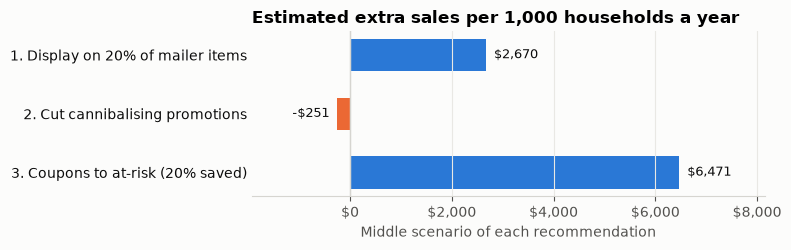

In [8]:
s = summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 2.6))
colors = [BLUE if v >= 0 else ORANGE for v in s["extra_sales_per_1000_hh_yr"]]
ax.barh(s["recommendation"], s["extra_sales_per_1000_hh_yr"], color=colors, height=0.55)
for y, v in zip(s["recommendation"], s["extra_sales_per_1000_hh_yr"]):
    ax.text(v, y, f"  {'-' if v < 0 else ''}${abs(v):,.0f}  ", va="center", ha="left" if v >= 0 else "right", color=INK, fontsize=9)
ax.axvline(0, color="#d6d5d0", linewidth=1)
ax.margins(x=0.25)
ax.tick_params(axis="y", length=0)
ax.set_title("Estimated extra sales per 1,000 households a year")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.set_xlabel("Middle scenario of each recommendation")
fig.tight_layout()
fig.savefig("../docs/charts/recommendation_impact.png", dpi=150)
plt.show()

## 6. Recommendation 4: test the coupon idea before rolling it out

### Why a test, after all that analysis?
My difference-in-differences in Part 2 couldn't measure the campaigns, because the households that got them were already changing before the campaign started. Brightbasket chose who to target, so I can't separate the campaign from the reasons it chose them. A randomised test fixes that: a coin decides who gets the offer, so the two groups are alike in everything except the offer.

### The design
- **Hypothesis:** sending at-risk households a coupon offer raises their weekly spend over the next 8 weeks, compared with households who don't get it.
- **Who:** households that are At risk or carry the churn flag. A random half gets the offer (test), the other half doesn't (control). I split within each segment so both groups have the same mix.
- **Primary metric:** average weekly spend per household over 8 weeks, counting $0 for weeks with no trip.
- **Secondary:** share of households still shopping after 8 weeks; coupon cost per household.
- **Duration:** 8 weeks of offer, plus 4 weeks after, to catch any dip once the coupons stop.

### How many households do I need?
That depends on how noisy weekly spend is. I measure it on the same kind of households in the last 8 full weeks of the data (weeks 94-101).

In [9]:
pool = hh[(hh["segment"] == "At risk") | hh["churn_risk"]]
weekly = pd.read_sql("""
    SELECT household_key, SUM(basket_value) AS spend
    FROM clean.baskets
    WHERE week_no BETWEEN 94 AND 101
    GROUP BY household_key""", engine)
spend = (weekly.set_index("household_key")["spend"]
         .reindex(pool["household_key"], fill_value=0) / 8)

mean, sd = spend.mean(), spend.std()
print(f"Test pool in this data: {len(pool)} households")
print(f"Average weekly spend: ${mean:.2f}, standard deviation ${sd:.2f}")

power = TTestIndPower()
sizes = pd.DataFrame({"lift_to_detect": [0.05, 0.10, 0.15, 0.20]})
sizes["lift_dollars_per_week"] = sizes["lift_to_detect"] * mean
sizes["households_per_group"] = [int(np.ceil(power.solve_power(effect_size=l * mean / sd, alpha=0.05, power=0.8)))
                                  for l in sizes["lift_to_detect"]]
sizes["total_households"] = sizes["households_per_group"] * 2
sizes.round(2)

Test pool in this data: 701 households
Average weekly spend: $13.29, standard deviation $19.41


,lift_to_detect,lift_dollars_per_week,households_per_group,total_households
0,0.05,0.66,13391,26782
1,0.10,1.33,3349,6698
2,0.15,1.99,1489,2978
3,0.20,2.66,838,1676


The same check for the secondary metric: if about 68% of flagged households keep shopping today (my backtest), how many do I need to see that rise by 5 points?

In [10]:
base_keep = 1 - CHURN_IF_FLAGGED
n_keep = NormalIndPower().solve_power(effect_size=proportion_effectsize(base_keep + 0.05, base_keep),
                                     alpha=0.05, power=0.8)
print(f"To detect {base_keep:.0%} -> {base_keep + 0.05:.0%} still shopping: {np.ceil(n_keep):,.0f} households per group")

To detect 68% -> 73% still shopping: 1,304 households per group


### How I'd read the result
- **The number:** difference in average weekly spend (test minus control), with its 95% confidence interval.
- **Statistically significant** means the interval doesn't include $0: the offer did something.
- **Practically significant** means the whole interval sits above break-even: the extra spend covers the coupon cost per household. A lift can be real and still not be worth paying for.
- **Decision:** roll out if the lower end of the interval clears break-even. If the interval is above $0 but straddles break-even, run longer or try a cheaper offer. If it includes $0, keep the money.
- **Before reading anything:** check the two groups looked alike before the test (spend, trips, segment mix), and that every household stayed in the group it was assigned to.

## What I found

1. **Putting a display next to more mailer items is the best move.** Turning 20% of mailer-only weeks into display + mailer weeks adds about $13.4K of extra sales over two years for $6.1K more discount. That's $2.19 of extra sales per extra discount dollar, or $2,670 a year per 1,000 households. It needs about 21% more display space, and that's the real limit.
2. **Moving interior-page features to the front page doesn't pay.** It adds $0.51 a week in extra sales but $0.70 in discount: $0.73 per extra discount dollar. The front page sells more mostly because it's discounted harder.
3. **Cutting promotions where they only shift sales around is a small win, not a headline.** In Cosmetics, Floral, Nutrition and packaged Seafood, cutting them saves $1,612 of discount and gives up $1,255 of real extra sales over two years. Worth doing, but it barely moves the total.
4. **Coupons for at-risk households have the biggest upside, and the least proof.** The 355 at-risk households are expected to take about $80.9K a year with them as they leave. If an offer saves 20% of that, it keeps $16.2K a year ($6,471 per 1,000 households), for the roughly $854 a year of coupons that now go to Champions. Break-even is saving just 1%, but nothing so far shows the offer saves anyone, so it goes to a test first.
5. **The test needs far more households than this sample has.** Weekly spend among at-risk and churn-flagged households is very noisy ($13.29 average, $19.41 standard deviation). To detect a 10% lift ($1.33 a week) with 80% power, I need about 3,350 households per group, 6,700 in total. This data has only 701 such households, so the test has to run across the chain's whole loyalty base, for 8 weeks plus 4 weeks of follow-up.
6. **Retention needs a similar size.** About 1,300 households per group are needed to see the share still shopping move from 68% to 73%.